In [2]:
import subprocess #used to run system commands from script

#libaries used to interogate results
import cymetric as cym 
from cymetric import graphs as cgr
from cymetric import timeseries

#Matplotlib is a python library for plotting graphs
import matplotlib.pyplot as plt

#Run cyclus
subprocess.run(["cyclus", "Question1_Cyclus_Script.xml"])


/root/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


              :                                                               
          .CL:CC CC             _Q     _Q  _Q_Q    _Q    _Q              _Q   
        CC;CCCCCCCC:C;         /_\)   /_\)/_/\\)  /_\)  /_\)            /_\)  
        CCCCCCCCCCCCCl       __O|/O___O|/O_OO|/O__O|/O__O|/O____________O|/O__
     CCCCCCf     iCCCLCC     /////////////////////////////////////////////////
     iCCCt  ;;;;;.  CCCC                                                      
    CCCC  ;;;;;;;;;. CClL.                          c                         
   CCCC ,;;       ;;: CCCC  ;                   : CCCCi                       
    CCC ;;         ;;  CC   ;;:                CCC`   `C;                     
  lCCC ;;              CCCC  ;;;:             :CC .;;. C;   ;    :   ;  :;;   
  CCCC ;.              CCCC    ;;;,           CC ;    ; Ci  ;    :   ;  :  ;  
   iCC :;               CC       ;;;,        ;C ;       CC  ;    :   ; .      
  CCCi ;;               CCC        ;;;.      .C ;   

Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental
Experimental Warning: MatlSellPolicy is experimental and its API may be subject to change
Experimental Warning: the Mixer archetype is experimental



Status: Cyclus run successful!
Output location: cyclus.sqlite
Simulation ID: 16400610-fc4f-4de6-9ba3-fb1fe87e4106


CompletedProcess(args=['cyclus', 'Question1_Cyclus_Script.xml'], returncode=0)

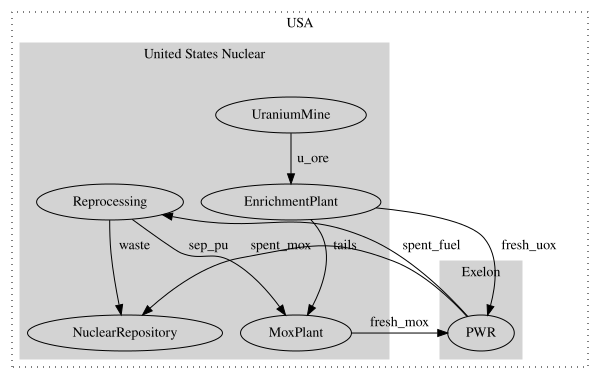

In [3]:
#Open up the Python Database
cdb = cym.dbopen("cyclus.sqlite")
ev = cym.Evaluator(db=cdb,write=False)

#Draw the Cycle Diagram
cgr.flow_graph(ev, label='comm')

In [2]:
#want the uranium requirement from the mine over time
#This creates a Pandas Dataframe
u=cym.filters.transactions_nuc(ev,commodities=["u_ore"])

#Sum up the nuclides
u = u.groupby("Time")[["Mass"]].sum()

#for plotting in excel
u.to_csv("mined_u.csv")

#plot cumulative in python
u=u.cumsum()
u.plot(y="Mass")

NameError: name 'ev' is not defined

In [13]:
"""There are more elegant ways to output data than using CSV files
The data is stored in dataframes (from the python Pandas library)
But we use CSV as it is simpler"""

#Output all transactions
cym.filters.transactions_nuc(ev).to_csv("transactions.csv")

#look at how tails builds up in MoxPlant and a small amount is then used to make fuel when the Pu is available
m = cym.filters.inventories(ev,facilities=["MoxPlant"])
m = m[m["InventoryName"] == "in_stream_1"].groupby("Time")[["Quantity"]].sum()
m.to_csv("tails_inventory.csv")

m = cym.filters.inventories(ev,facilities=["MoxPlant"])
m = m[m["InventoryName"] == "in_stream_0"].groupby("Time")[["Quantity"]].sum()
m.to_csv("pu_inventory.csv")

Problem 1 -   Flow goes from Uranium mine to enrichment plant. Path splits. One goes to PWR, the other goes to the Nuclear Repository   
What is different?  
